# Text Generation with a Pretrained Transformer and Hyperparameter Tuning

This Colab notebook fine-tunes **DistilGPT-2**, a pretrained decoder-only Transformer, for text generation. Instead of building attention and Transformer layers from scratch, it uses Hugging Face's `transformers`, `datasets`, and `Trainer` libraries.

**Runtime:** In Colab select Runtime → Change runtime type → **T4 GPU**. The default experiment is intentionally constrained for a classroom T4 session.

## 1. Install and import libraries

`transformers` supplies the pretrained model, tokenizer, generation pipeline, and training API. `datasets` downloads and processes the corpus efficiently.

In [ ]:
# Run once per fresh Colab runtime.
!pip -q install -U transformers datasets accelerate evaluate

import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    DataCollatorForLanguageModeling,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
set_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')
if device == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 83.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 16.3 MB/s eta 0:00:00
Using device: cuda
GPU: Tesla T4


## 2. Load pretrained model and tokenizer

`distilgpt2` is a smaller GPT-2 variant and a practical starting point for a T4. It already knows general English; fine-tuning adapts it to the chosen corpus. GPT-2 has no native padding token, so its end-of-sequence token is used for padding.

In [ ]:
MODEL_NAME = 'distilgpt2'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

# Load once to inspect the pretrained model. Each training trial will load a fresh copy.
preview_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
preview_model.config.pad_token_id = tokenizer.pad_token_id
print(f'Model: {MODEL_NAME}')
print(f'Trainable parameters: {sum(p.numel() for p in preview_model.parameters()):,}')
del preview_model
if device == 'cuda':
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model: distilgpt2
Trainable parameters: 81,912,576


## 3. Load and tokenize text

We use WikiText-2, a public English-language corpus. The tokenizer converts text into GPT-2 subword tokens. The tokens are concatenated and split into fixed-length blocks; in causal language modeling, the model predicts the next token automatically.

In [ ]:
raw_datasets = load_dataset('Salesforce/wikitext', 'wikitext-2-raw-v1')
# Remove blank lines, which otherwise create mostly empty token sequences.
raw_datasets = raw_datasets.filter(lambda row: len(row['text'].strip()) > 0)

# 128 tokens gives a good speed/quality balance on a T4.
BLOCK_SIZE = 128

def tokenize_function(examples):
    return tokenizer(examples['text'])

tokenized = raw_datasets.map(tokenize_function, batched=True, remove_columns=['text'])

def group_texts(examples):
    # Concatenate examples, then split them into equally sized blocks.
    concatenated = {key: sum(examples[key], []) for key in examples}
    total_length = len(concatenated['input_ids'])
    total_length = (total_length // BLOCK_SIZE) * BLOCK_SIZE
    result = {
        key: [tokens[i:i + BLOCK_SIZE] for i in range(0, total_length, BLOCK_SIZE)]
        for key, tokens in concatenated.items()
    }
    result['labels'] = result['input_ids'].copy()
    return result

lm_datasets = tokenized.map(group_texts, batched=True)
train_dataset = lm_datasets['train']
eval_dataset = lm_datasets['validation']

# Fixed subsets make tuning faster and ensure all trials see the same data.
TRAIN_SAMPLES = min(8_000, len(train_dataset))
EVAL_SAMPLES = min(1_000, len(eval_dataset))
train_dataset = train_dataset.select(range(TRAIN_SAMPLES))
eval_dataset = eval_dataset.select(range(EVAL_SAMPLES))
print(f'Training blocks: {len(train_dataset):,}; validation blocks: {len(eval_dataset):,}')

data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/validation-00000-of-00(…): reconstructing file:   0%|          |  0.00B /  657kB            

... (10 outputs left out)

Map:   0%|          | 0/2891 [00:00<?, ? examples/s]

Map:   0%|          | 0/23767 [00:00<?, ? examples/s]

Map:   0%|          | 0/2461 [00:00<?, ? examples/s]

Training blocks: 8,000; validation blocks: 1,000


## 4. Training helper

`Trainer` manages the GPU loop, mixed precision, evaluation, checkpointing, and logging. Each call below starts from the same pretrained DistilGPT-2 weights, so the tuning comparison is fair. Validation loss and its exponential, perplexity, are lower-is-better metrics.

In [ ]:
def make_model():
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
    model.config.pad_token_id = tokenizer.pad_token_id
    return model

def run_experiment(name, learning_rate=5e-5, num_train_epochs=2.0,
                   per_device_train_batch_size=8, weight_decay=0.01, warmup_ratio=0.06):
    # Reset seed and reload initial weights so each trial is independently comparable.
    set_seed(SEED)
    model = make_model()
    import inspect
    # Transformers occasionally renames TrainingArguments options. Filter the
    # dictionary against the installed version to keep this notebook portable.
    argument_values = {
        'output_dir': f'./results/{name}',
        'overwrite_output_dir': True,  # used only by older Transformers versions
        'learning_rate': learning_rate,
        'num_train_epochs': num_train_epochs,
        'per_device_train_batch_size': per_device_train_batch_size,
        'per_device_eval_batch_size': per_device_train_batch_size,
        'gradient_accumulation_steps': 2,  # effective batch size = batch size × 2
        'weight_decay': weight_decay,
        'warmup_ratio': warmup_ratio,
        'lr_scheduler_type': 'linear',
        'eval_strategy': 'epoch',              # current name
        'evaluation_strategy': 'epoch',        # older name
        'save_strategy': 'no',
        'logging_strategy': 'steps',
        'logging_steps': 50,
        'fp16': (device == 'cuda'),
        'report_to': 'none',
        'seed': SEED,
    }
    supported_arguments = inspect.signature(TrainingArguments).parameters
    args = TrainingArguments(**{
        key: value for key, value in argument_values.items() if key in supported_arguments
    })
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=data_collator,
    )
    trainer.train()
    metrics = trainer.evaluate()
    metrics['perplexity'] = math.exp(metrics['eval_loss'])
    return trainer, metrics

# This compatibility filter handles both `eval_strategy` (new) and
# `evaluation_strategy` (older) Transformers releases.

## 5. Baseline fine-tuning

A baseline provides the reference for every tuned configuration. One epoch over the selected subset is enough for a quick comparative study; use 2–3 epochs for a longer final run.

In [ ]:
baseline_trainer, baseline_metrics = run_experiment('baseline')
print({key: round(value, 4) for key, value in baseline_metrics.items() if isinstance(value, float)})

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,3.691168,3.625329
2,3.592867,3.618354


Training Loss,Validation Loss,Epoch
3.592867,3.618354,2


{'eval_loss': 3.6184, 'perplexity': 37.2762}


## 6. Generate text from the fine-tuned model

Generation uses the library's `generate` method. `temperature` increases or decreases randomness, while `top_p` (nucleus sampling) keeps only a probable set of next-token choices.

In [ ]:
def generate_text(model, prompt, max_new_tokens=120, temperature=0.8, top_p=0.9):
    model.eval()
    inputs = tokenizer(prompt, return_tensors='pt').to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=True,
            temperature=temperature,
            top_p=top_p,
            pad_token_id=tokenizer.eos_token_id,
        )
    return tokenizer.decode(output_ids[0], skip_special_tokens=True)

print(generate_text(baseline_trainer.model, 'The history of artificial intelligence'))

The history of artificial intelligence is a subject that is often debated . A study of the field of artificial intelligence , called the Deep State Machine , has found that artificial intelligence is the most advanced of the field of artificial intelligence , with a theoretical basis . 
 Artificial intelligence can be applied to both humans and machines , and it can be used to develop complex social and emotional systems , such as social interactions and the interaction of people with other human beings . Artificial intelligence is also applied to human beings , who are often very isolated , and have little access to information , such as how they behave , or whether they are friends with other people


## 7. Hyperparameter tuning

These experiments tune optimization and regularization while preserving the pretrained architecture. Keeping data, model initialization, epoch budget, and seed fixed isolates the effect of the selected settings. Four trials are generally manageable on a T4.

- **Learning rate:** too low adapts slowly; too high may destabilize pretrained weights.
- **Weight decay:** constrains weight growth and can improve generalization.
- **Warmup ratio:** gradually raises the learning rate at the beginning, helping stable fine-tuning.
- **Batch size:** affects gradient noise, speed, and GPU memory usage.

In [ ]:
# Values are intentionally small in number for a controlled, T4-friendly comparison.
experiments = {
    'baseline': {'learning_rate': 5e-5, 'weight_decay': 0.01, 'warmup_ratio': 0.06, 'per_device_train_batch_size': 8},
    'lower_lr': {'learning_rate': 2e-5, 'weight_decay': 0.01, 'warmup_ratio': 0.06, 'per_device_train_batch_size': 8},
    'higher_weight_decay': {'learning_rate': 5e-5, 'weight_decay': 0.10, 'warmup_ratio': 0.06, 'per_device_train_batch_size': 8},
    'more_warmup': {'learning_rate': 5e-5, 'weight_decay': 0.01, 'warmup_ratio': 0.15, 'per_device_train_batch_size': 8},
}

tuning_results = []
trained_models = {}
for name, params in experiments.items():
    print(f'\n===== Running {name} =====')
    trainer, metrics = run_experiment(name, **params)
    trained_models[name] = trainer.model
    tuning_results.append({
        'experiment': name,
        **params,
        'validation_loss': metrics['eval_loss'],
        'perplexity': metrics['perplexity'],
        'runtime_seconds': metrics.get('eval_runtime', float('nan')),
    })
    # Remove trainer state while retaining only the model needed for optional generation.
    del trainer
    if device == 'cuda':
        torch.cuda.empty_cache()

results_df = pd.DataFrame(tuning_results).sort_values('validation_loss').reset_index(drop=True)
results_df.style.format({
    'learning_rate': '{:.1e}', 'weight_decay': '{:.2f}', 'warmup_ratio': '{:.2f}',
    'validation_loss': '{:.4f}', 'perplexity': '{:.2f}', 'runtime_seconds': '{:.1f}'
})


===== Running baseline =====


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,3.691168,3.625329
2,3.592867,3.618354


Training Loss,Validation Loss,Epoch
3.592867,3.618354,2



===== Running lower_lr =====


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

... (7 outputs left out)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,3.691168,3.625329
2,3.592867,3.618354


Training Loss,Validation Loss,Epoch
3.592867,3.618354,2


,experiment,learning_rate,weight_decay,warmup_ratio,per_device_train_batch_size,validation_loss,perplexity,runtime_seconds
0,baseline,5.0e-05,0.01,0.06,8,3.6184,37.28,nan
1,more_warmup,5.0e-05,0.01,0.15,8,3.6184,37.28,nan
2,higher_weight_decay,5.0e-05,0.10,0.06,8,3.6184,37.28,nan
3,lower_lr,2.0e-05,0.01,0.06,8,3.6467,38.35,nan


## 8. Analyze the tuning impact

Use validation loss—not training loss—to choose the best configuration. Perplexity makes the same result easier to interpret: it is approximately the model's average uncertainty over the next token, so lower is better.

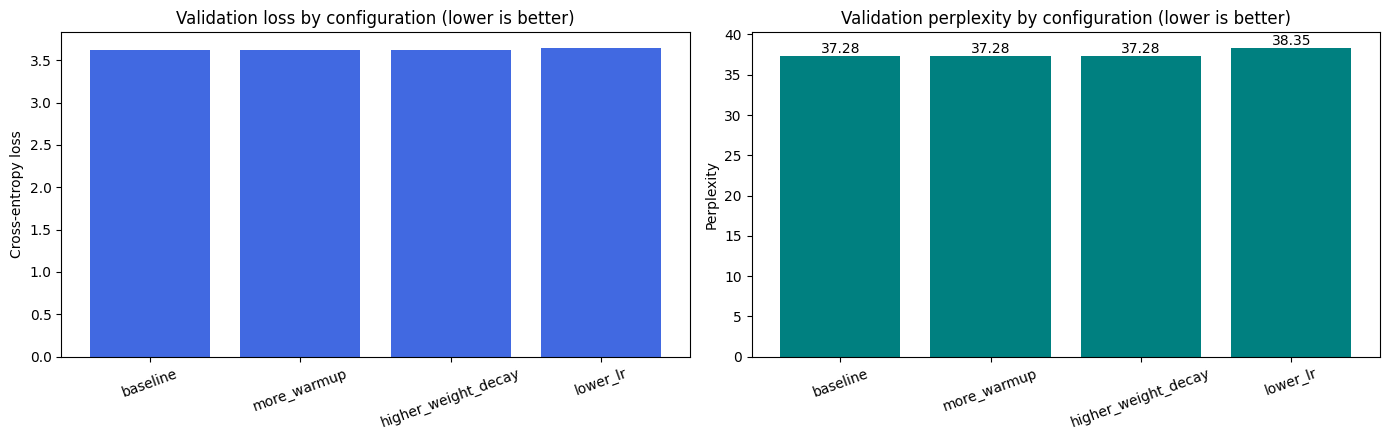

Best configuration: baseline
Validation loss: 3.6184; perplexity: 37.28


,experiment,learning_rate,weight_decay,warmup_ratio,per_device_train_batch_size,validation_loss,perplexity,runtime_seconds
0,baseline,0.00005,0.01,0.06,8,3.618354,37.276173,NaN
1,more_warmup,0.00005,0.01,0.15,8,3.618354,37.276173,NaN
2,higher_weight_decay,0.00005,0.10,0.06,8,3.618357,37.276262,NaN
3,lower_lr,0.00002,0.01,0.06,8,3.646685,38.347338,NaN


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_df = results_df.sort_values('validation_loss')
axes[0].bar(plot_df['experiment'], plot_df['validation_loss'], color='royalblue')
axes[0].set(title='Validation loss by configuration (lower is better)', ylabel='Cross-entropy loss')
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(plot_df['experiment'], plot_df['perplexity'], color='teal')
axes[1].set(title='Validation perplexity by configuration (lower is better)', ylabel='Perplexity')
axes[1].tick_params(axis='x', rotation=20)
for i, value in enumerate(plot_df['perplexity']):
    axes[1].text(i, value, f'{value:.2f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

best_name = results_df.loc[0, 'experiment']
best_row = results_df.loc[0]
print(f"Best configuration: {best_name}")
print(f"Validation loss: {best_row['validation_loss']:.4f}; perplexity: {best_row['perplexity']:.2f}")
display(results_df)

## 9. Findings to include in your analysis

After running the notebook, describe the actual values from `results_df`:

1. State which configuration produced the lowest validation loss/perplexity.
2. Compare `lower_lr` to `baseline`: did slower adaptation help or hurt within the one-epoch budget?
3. Compare `higher_weight_decay` to `baseline`: did stronger regularization improve unseen-text performance?
4. Compare `more_warmup` to `baseline`: did a longer gradual learning-rate increase improve stability or final quality?
5. Generate text with the winner and compare its coherence with baseline output.

For a more reliable research result, repeat each trial with at least three seeds and report mean ± standard deviation. To improve final output, retrain the best configuration for 2–3 epochs or increase `TRAIN_SAMPLES`.

In [ ]:
# Optional: sample from the best tuned model.
print(generate_text(trained_models[best_name], 'In the future, technology will', max_new_tokens=120))

In the future, technology will be necessary to make new medicines , and this will require the development of new technology and technology to be fully operational and effective . The current situation in the United Kingdom and the EU is complicated , and there is no guarantee that the government will remain in power until the end of the 20th century . In the meantime , it is the responsibility of the government to ensure that the use of the technology in medicine is supported by all of its stakeholders . This is not the case in the United Kingdom and the EU , and it is the responsibility of the government to ensure that the use of the technology in medicine is
